# Exploration in RL: ε-greedy vs. RND

A DQN agent explores the **diabolical combination lock** (Misra et al., 2020) in two ways:
- **ε-greedy only:** act randomly with probability ε.
- **ε-greedy + RND:** the same agent plus a Random Network Distillation bonus (Burda et al., 2019).

Everything else is identical.

**In this notebook:**
1. **Setup:** imports and seeding.
2. **Environment:** the diabolical combination lock.
3. **Agents:** a DQN agent with ε-greedy exploration, and an optional RND bonus.
4. **Experiment:** both agents on $H = 5, 10, 15$: performance during training, an evaluation of the learned policy, and the size of the RND bonus.
5. **Discussion:** what the results show and how they connect to UCB.

## 1. Setup

In [ ]:
import copy
import random
from collections import deque

import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn as nn

SEED = 42


def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)

## 2. Environment: the diabolical combination lock

Based on Misra et al.'s code (`microsoft/Intrepid`), with a single good chain.

- **States:** a good state $s_{h,a}$ and a bad state $s_{h,b}$ at each step $h$. The agent starts in $s_{1,a}$.
- **Dynamics:** in a good state, the correct action $u_h$ moves on to $s_{h+1,a}$. Any other action falls into the bad chain, which the agent cannot leave. Episodes always last $H$ steps.
- **Rewards:** $5$ for the correct last action, a misleading $0.1 \times \text{Bernoulli}(1/2)$ for falling into the bad chain, and $0$ otherwise.
- **Observations:** a noisy one-hot encoding of the state and the step, $x = R\,([e_s; e_h] + \varepsilon)$ with $\varepsilon \sim \mathcal{N}(0, 0.1^2 I)$. The Hadamard matrix $R$ projects it into a higher-dimensional space and mixes all coordinates, so no single entry reveals the state.

Random actions open the lock with probability $|\mathcal{A}|^{-H}$.

<img src="figures/combination_lock.png" alt="Diabolical combination lock" width="900">

In [ ]:
def hadamard(n_cols):
    """Sylvester Hadamard matrix with +/-1 entries, d >= n_cols rows, trimmed to n_cols columns."""
    H = np.ones((1, 1))
    while H.shape[0] < n_cols:
        H = np.block([[H, H], [H, -H]])
    return H[:, :n_cols]


class DiabolicalCombinationLock:
    GOOD, BAD = 0, 2          # state-type slots; slot 1 (the paper's second good chain) is unused

    def __init__(self, horizon, n_actions, noise_std=0.1, final_reward=5.0, anti_shaped_reward=0.1):
        self.horizon, self.n_actions = horizon, n_actions
        self.noise_std, self.final_reward, self.anti_shaped_reward = noise_std, final_reward, anti_shaped_reward
        self.u = np.random.randint(n_actions, size=horizon)        # the correct action at each step
        self.rng = np.random.default_rng(np.random.randint(2**31))  # for noise and rewards
        self.R = hadamard(3 + horizon + 1)                          # maps [one-hot type; one-hot step]
        self.observation_dim = self.R.shape[0]

    def reset(self):
        self.h, self.state = 0, self.GOOD
        return self._observe()

    def _observe(self):
        x = np.zeros(self.R.shape[1])
        x[self.state] = 1.0
        x[3 + self.h] = 1.0
        x += self.rng.normal(0.0, self.noise_std, size=x.shape)
        return torch.as_tensor(self.R @ x, dtype=torch.float32)     # observations are PyTorch tensors

    def step(self, action):
        in_good = self.state == self.GOOD
        correct_action = action == self.u[self.h]
        reward = 0.0
        if in_good and correct_action and self.h == self.horizon - 1:  # correct last action: the lock opens
            reward = self.final_reward
        if in_good and not correct_action:                      # wrong action: fall into the bad chain
            reward = self.anti_shaped_reward * (self.rng.random() < 0.5)
            self.state = self.BAD
        self.h += 1
        done = self.h == self.horizon
        return self._observe(), reward, done, {"solved": done and self.state == self.GOOD}

In [ ]:
# Sanity check: the optimal policy collects the final reward; a policy that always errs does not.
env = DiabolicalCombinationLock(horizon=5, n_actions=3)
print("correct actions:", env.u, "| observation dim:", env.observation_dim)

for name, policy in [("optimal", lambda: env.u[env.h]), ("always wrong", lambda: (env.u[env.h] + 1) % 3)]:
    env.reset()
    done, ret = False, 0.0
    while not done:
        _, r, done, info = env.step(policy())
        ret += r
    print(f"{name:13s} return {ret:.1f}, solved {info['solved']}")

correct actions: [1 1 2 2 0] | observation dim: 16
optimal       return 5.0, solved True
always wrong  return 0.1, solved False


## 3. Agents

**ε-greedy DQN.** Q-learning with a replay buffer and a target network. It acts randomly with a small fixed probability ε.

**RND bonus.** A fixed random *target* network $f^*$ and a *predictor* $\hat f_\theta$ trained to match it on visited states. The prediction error

$$r_{\text{int}}(s) = \|\hat f_\theta(s) - f^*(s)\|^2$$

is large on unfamiliar states, like an inverse visit count. The agent learns from $r_{\text{ext}} + \beta\, r_{\text{int}}$.

Details: the bonus averages several (target, predictor) heads, and is recomputed from the current predictor each time a batch is sampled. By default it is divided by the running std of the error (as in Burda et al.); with `normalize=False` the raw error is used directly. `target_noise` (off here) adds noise to the predictor's training labels.

In [ ]:
def mlp(in_dim, out_dim, hidden=128):
    return nn.Sequential(nn.Linear(in_dim, hidden), nn.ReLU(),
                         nn.Linear(hidden, hidden), nn.ReLU(),
                         nn.Linear(hidden, out_dim))


class RunningStats:
    """Running mean and variance of a stream of batches."""

    def __init__(self, shape=()):
        self.mean, self.var, self.count = torch.zeros(shape), torch.ones(shape), 1e-4

    def update(self, batch):
        n, delta = len(batch), batch.mean(0) - self.mean
        total = self.count + n
        self.var = (self.var * self.count + batch.var(0, unbiased=False) * n + delta**2 * self.count * n / total) / total
        self.mean = self.mean + delta * n / total
        self.count = total

In [ ]:
class RND:
    """Random Network Distillation with `n_heads` (target, predictor) pairs."""

    def __init__(self, obs_dim, n_heads=5, out_dim=64, lr=5e-4, normalize=True, target_noise=0.0):
        self.targets = [mlp(obs_dim, out_dim).requires_grad_(False) for _ in range(n_heads)]
        self.predictors = nn.ModuleList([mlp(obs_dim, out_dim) for _ in range(n_heads)])
        self.optimizer = torch.optim.Adam(self.predictors.parameters(), lr=lr)
        self.normalize = normalize                       # divide the bonus by the running std of the error
        self.target_noise = target_noise                 # label-noise std, relative to the targets' std
        self.obs_stats, self.err_stats = RunningStats(obs_dim), RunningStats()

    def _normalize(self, obs):
        return ((obs - self.obs_stats.mean) / (self.obs_stats.var + 1e-8).sqrt()).clamp(-5, 5)

    @torch.no_grad()
    def _error(self, obs):
        """Squared prediction error per observation, averaged over heads."""
        x = self._normalize(obs)
        errors = [((target(x) - predictor(x)) ** 2).sum(1)
                  for target, predictor in zip(self.targets, self.predictors)]
        return sum(errors) / len(errors)                 # average over heads

    def bonus(self, obs):
        """Bonus for a batch of observations: the raw error, or the normalized error. Read-only."""
        error = self._error(obs)
        if self.normalize:
            error = (error / (self.err_stats.var + 1e-8).sqrt()).clamp(0, 5)
        return error

    def observe(self, obs):
        """Register a freshly visited observation: update the statistics; return (raw error, bonus)."""
        obs = obs[None]
        self.obs_stats.update(obs)
        error = self._error(obs)
        self.err_stats.update(error)
        return error.item(), self.bonus(obs).item()

    def train_step(self, obs):
        x = self._normalize(obs)
        loss = 0.0
        for target, predictor in zip(self.targets, self.predictors):
            with torch.no_grad():
                y = target(x)
                y = y + self.target_noise * y.std() * torch.randn_like(y)   # no-op when target_noise = 0
            loss = loss + ((predictor(x) - y) ** 2).sum(1).mean()
        self.optimizer.zero_grad()
        (loss / len(self.targets)).backward()
        nn.utils.clip_grad_norm_(self.predictors.parameters(), 1.0)
        self.optimizer.step()

In [ ]:
class DQNAgent:
    """DQN with ε-greedy exploration. Pass an `RND` instance to add its exploration bonus."""

    def __init__(self, obs_dim, n_actions, epsilon=0.01, rnd=None, beta=0.1,
                 gamma=0.99, lr=1e-3, batch_size=64, buffer_size=10_000, target_every=50):
        self.n_actions, self.gamma, self.batch_size = n_actions, gamma, batch_size
        self.epsilon = epsilon                       # fixed exploration rate
        self.rnd, self.beta = rnd, beta
        self.q, self.q_target = mlp(obs_dim, n_actions), mlp(obs_dim, n_actions)
        self.q_target.load_state_dict(self.q.state_dict())
        self.optimizer = torch.optim.Adam(self.q.parameters(), lr=lr)
        self.buffer = deque(maxlen=buffer_size)
        self.target_every, self.n_updates = target_every, 0

    def greedy_action(self, obs):
        with torch.no_grad():
            return self.q(obs).argmax().item()

    def act(self, obs):
        if random.random() < self.epsilon:
            return random.randrange(self.n_actions)
        return self.greedy_action(obs)

    def train(self):
        if len(self.buffer) < self.batch_size:
            return
        obs, actions, rewards, next_obs, dones = zip(*random.sample(self.buffer, self.batch_size))
        obs, next_obs = torch.stack(obs), torch.stack(next_obs)
        actions, rewards, dones = torch.tensor(actions), torch.tensor(rewards), torch.tensor(dones)
        if self.rnd is not None:
            rewards = rewards + self.beta * self.rnd.bonus(next_obs)   # bonus from the current predictor
            self.rnd.train_step(obs)                                   # then train it on visited states

        q_values = self.q(obs)                                   # shape (batch, n_actions)
        q = q_values[torch.arange(len(actions)), actions]        # Q(s, a) for the action taken in each row
        with torch.no_grad():
            target = rewards + self.gamma * (1 - dones) * self.q_target(next_obs).max(1).values
        loss = nn.functional.mse_loss(q, target)
        self.optimizer.zero_grad()
        loss.backward()
        self.optimizer.step()

        self.n_updates += 1
        if self.n_updates % self.target_every == 0:
            self.q_target.load_state_dict(self.q.state_dict())

In [ ]:
def evaluate(env, agent, n_episodes=5):
    """Success rate of the greedy policy (ε = 0). No learning happens here."""
    successes = 0
    for _ in range(n_episodes):
        obs, done = env.reset(), False
        while not done:
            obs, _, done, info = env.step(agent.greedy_action(obs))
        successes += info["solved"]
    return successes / n_episodes


def train(env, agent, n_episodes, eval_every=100):
    """Train for `n_episodes`; every `eval_every` episodes, evaluate the greedy policy.
    Returns per-episode training success and returns, and the evaluation success rates."""
    eval_env = copy.deepcopy(env)        # same lock, separate randomness: evaluation never changes training
    history = {"success": [], "ext_return": [], "int_return": [], "rnd_error": [], "eval_success": []}
    for episode in range(1, n_episodes + 1):
        obs, done, ext_return, int_return, rnd_error = env.reset(), False, 0.0, 0.0, 0.0
        while not done:
            action = agent.act(obs)
            next_obs, reward, done, info = env.step(action)
            if agent.rnd is not None:
                error, bonus = agent.rnd.observe(next_obs)
                int_return, rnd_error = int_return + bonus, rnd_error + error
            agent.buffer.append((obs, action, reward, next_obs, float(done)))
            agent.train()
            obs, ext_return = next_obs, ext_return + reward

        history["success"].append(float(info["solved"]))
        history["ext_return"].append(ext_return)
        history["int_return"].append(int_return)
        history["rnd_error"].append(rnd_error / env.horizon)     # mean raw prediction error per step
        if episode % eval_every == 0:
            history["eval_success"].append(evaluate(eval_env, agent))
    return {key: np.array(values) for key, values in history.items()}

## 4. Experiment

Both agents use ε = 0.01 on locks of horizon $H = 5, 10, 15$, with 400 episodes per step of horizon and five seeds. Plots show the mean over seeds, with a band of ± one standard error. We look at:
- **Performance during training** (4.1): the success rate of the training episodes, which still include random ε-actions.
- **The learned policy** (4.2): every 100 episodes, the agent plays 5 episodes greedily (ε = 0) without learning.
- **The size of the RND bonus** (4.3), compared with the environment's rewards.
- **The raw prediction error** (4.4), the novelty signal before any normalization.

We run two RND variants: the standard one, whose bonus is normalized by the running std of the error, and one that uses the **raw prediction error** directly.

We also print the episode of each run's first success.

In [ ]:
N_ACTIONS = 3
EPSILON = 0.01               # fixed exploration rate for both agents
BETAS = {"ε-greedy + RND": 0.1, "ε-greedy + RND (raw error)": 0.2}   # weight of the RND bonus
EPISODES_PER_STEP = 400      # episode budget per step of horizon
EVAL_EVERY = 100             # evaluate the greedy policy every 100 episodes
HORIZONS = [5, 10, 15]
SEEDS = [42, 142, 242, 342, 442]
AGENTS = ["ε-greedy only", "ε-greedy + RND", "ε-greedy + RND (raw error)"]
COLORS = dict(zip(AGENTS, ["#d62728", "#9467bd", "#2ca02c"]))


def run(agent_name, H, seed):
    # Train one agent on a fresh lock of horizon H; return its training history.
    set_seed(seed)
    env = DiabolicalCombinationLock(H, N_ACTIONS)
    rnd = RND(env.observation_dim, n_heads=H, normalize="raw" not in agent_name) if "RND" in agent_name else None
    agent = DQNAgent(env.observation_dim, N_ACTIONS, epsilon=EPSILON, rnd=rnd, beta=BETAS.get(agent_name, 0.0))
    return train(env, agent, EPISODES_PER_STEP * H, eval_every=EVAL_EVERY)


def first_success(history):
    hits = np.flatnonzero(history["success"])
    return int(hits[0]) if len(hits) else None

In [ ]:
results = {H: {name: [] for name in AGENTS} for H in HORIZONS}
for H in HORIZONS:
    for name in AGENTS:
        for seed in SEEDS:
            results[H][name].append(run(name, H, seed))
        firsts = [first_success(s) for s in results[H][name]]
        print(f"H = {H:2d} | {name:26s} | first success per seed: {firsts}")

H =  5 | ε-greedy only              | first success per seed: [1099, 89, 321, 232, 98]
H =  5 | ε-greedy + RND             | first success per seed: [57, 135, 39, 122, 138]
H =  5 | ε-greedy + RND (raw error) | first success per seed: [53, 695, 41, 249, 333]
H = 10 | ε-greedy only              | first success per seed: [2614, 965, 901, 1209, 953]
H = 10 | ε-greedy + RND             | first success per seed: [1222, 1108, 797, 486, 758]
H = 10 | ε-greedy + RND (raw error) | first success per seed: [1154, 846, 846, 2135, 560]
H = 15 | ε-greedy only              | first success per seed: [1101, 3298, 1322, 1279, 749]
H = 15 | ε-greedy + RND             | first success per seed: [962, 482, 1074, 509, 769]
H = 15 | ε-greedy + RND (raw error) | first success per seed: [678, 3546, 2187, 1373, 720]


### 4.1 Performance during training

Success rate of the training episodes. The dashed line is the best possible success while acting randomly 1% of the time; both agents reach it eventually, so what matters is **how fast**.

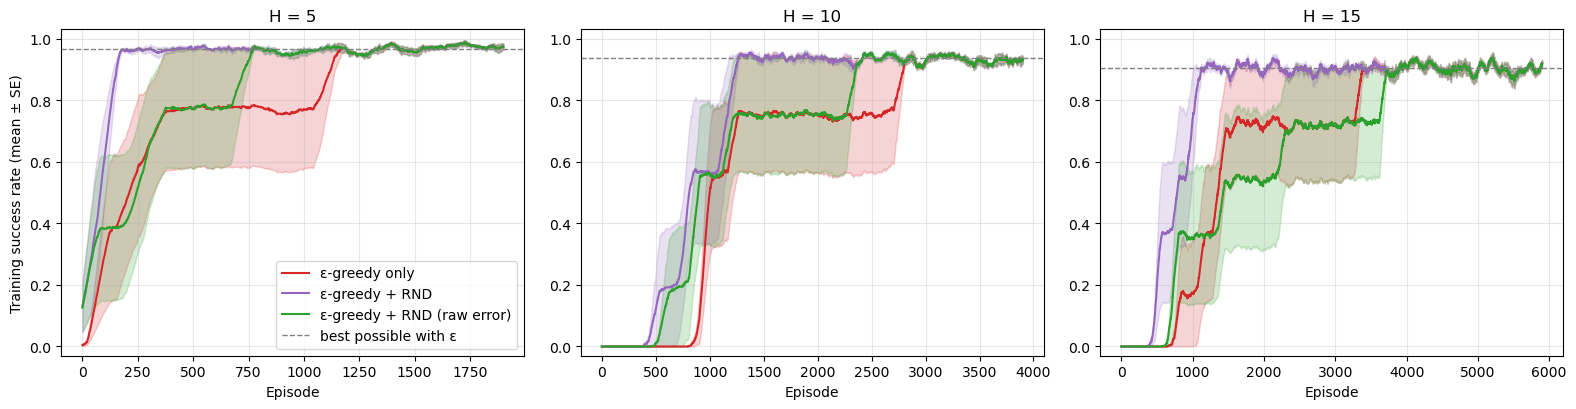

In [ ]:
def smooth(x, window=100):
    return np.convolve(x, np.ones(window) / window, mode="valid")


def plot_mean_se(ax, x, runs, **kwargs):
    # Mean over seeds (rows of runs), with a band of ± one standard error.
    mean, se = runs.mean(0), runs.std(0, ddof=1) / np.sqrt(len(runs))
    ax.plot(x, mean, **kwargs)
    ax.fill_between(x, mean - se, mean + se, color=kwargs["color"], alpha=0.2)


fig, axes = plt.subplots(1, len(HORIZONS), figsize=(5.3 * len(HORIZONS), 4.2), squeeze=False)
axes = axes[0]                                   # one panel per horizon
for ax, H in zip(axes, HORIZONS):
    for name in AGENTS:
        curves = np.array([smooth(h["success"]) for h in results[H][name]])
        episodes = np.arange(curves.shape[1])
        plot_mean_se(ax, episodes, curves, color=COLORS[name], label=name)
    best = (1 - EPSILON * (N_ACTIONS - 1) / N_ACTIONS) ** H
    ax.axhline(best, color="gray", linestyle="--", linewidth=1, label="best possible with ε")
    ax.set(title=f"H = {H}", xlabel="Episode", ylim=(-0.03, 1.03))
    ax.grid(alpha=0.3)
axes[0].set_ylabel("Training success rate (mean ± SE)")
axes[0].legend(loc="lower right")
plt.tight_layout()
plt.show()

### 4.2 Evaluation of the learned policy

Every 100 training episodes we pause learning and run the greedy policy (ε = 0) for 5 episodes on a copy of the lock. This shows when each agent has actually **learned** to open the lock, not just stumbled on it once. Without random actions, the best possible success is 100%.

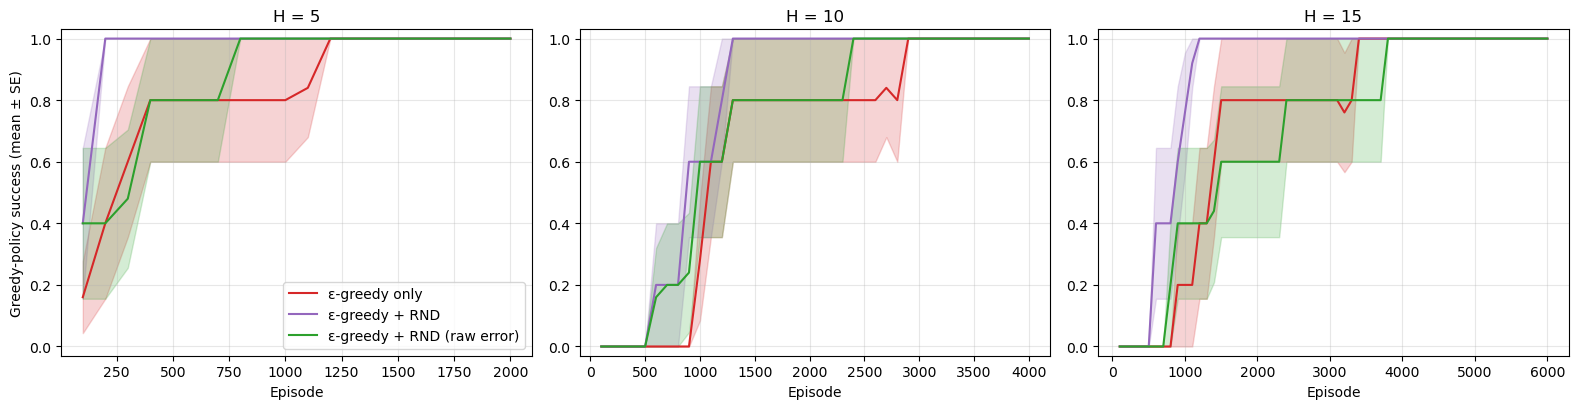

In [ ]:
fig, axes = plt.subplots(1, len(HORIZONS), figsize=(5.3 * len(HORIZONS), 4.2), squeeze=False)
axes = axes[0]
for ax, H in zip(axes, HORIZONS):
    for name in AGENTS:
        evals = np.array([h["eval_success"] for h in results[H][name]])
        episodes = EVAL_EVERY * np.arange(1, evals.shape[1] + 1)
        plot_mean_se(ax, episodes, evals, color=COLORS[name], label=name)
    ax.set(title=f"H = {H}", xlabel="Episode", ylim=(-0.03, 1.03))
    ax.grid(alpha=0.3)
axes[0].set_ylabel("Greedy-policy success (mean ± SE)")
axes[0].legend(loc="lower right")
plt.tight_layout()
plt.show()

### 4.3 Size of the RND bonus

The RND agents add $\beta\, r_{\text{int}}$ to every reward ($\beta = 0.1$ for the normalized bonus, $0.2$ for the raw error). Below is that weighted bonus per step, averaged over each episode, next to the environment's rewards: the misleading reward for falling into the bad chain ($0.05$ on average) and the final reward ($5$, once per successful episode). The normalized bonus drifts slightly upward late in training: the running std it is divided by shrinks even faster than the error itself.

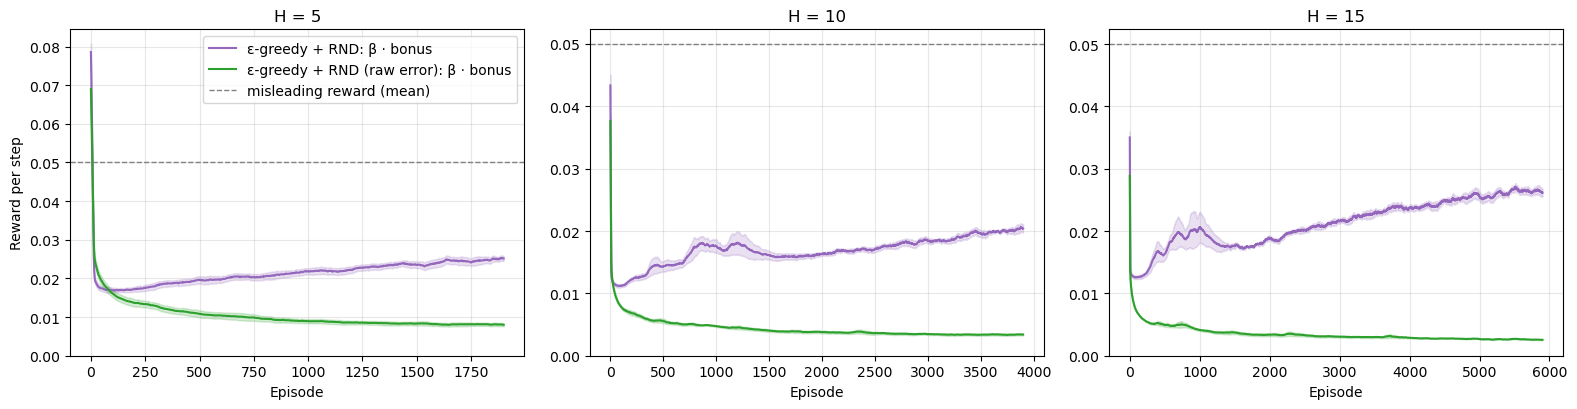

H =  5 | ε-greedy + RND             | β · bonus per step: first 100 episodes 0.079, last 100 episodes 0.025
H =  5 | ε-greedy + RND (raw error) | β · bonus per step: first 100 episodes 0.069, last 100 episodes 0.008
H = 10 | ε-greedy + RND             | β · bonus per step: first 100 episodes 0.043, last 100 episodes 0.020
H = 10 | ε-greedy + RND (raw error) | β · bonus per step: first 100 episodes 0.038, last 100 episodes 0.003
H = 15 | ε-greedy + RND             | β · bonus per step: first 100 episodes 0.035, last 100 episodes 0.026
H = 15 | ε-greedy + RND (raw error) | β · bonus per step: first 100 episodes 0.029, last 100 episodes 0.003


In [ ]:
fig, axes = plt.subplots(1, len(HORIZONS), figsize=(5.3 * len(HORIZONS), 4.2), squeeze=False)
axes = axes[0]
for ax, H in zip(axes, HORIZONS):
    for name in AGENTS[1:]:
        per_step = np.array([smooth(BETAS[name] * h["int_return"] / H) for h in results[H][name]])
        episodes = np.arange(per_step.shape[1])
        plot_mean_se(ax, episodes, per_step, color=COLORS[name], label=f"{name}: β · bonus")
    ax.axhline(0.05, color="gray", linestyle="--", linewidth=1, label="misleading reward (mean)")
    ax.set(title=f"H = {H}", xlabel="Episode", ylim=(0, None))
    ax.grid(alpha=0.3)
axes[0].set_ylabel("Reward per step")
axes[0].legend(loc="upper right")
plt.tight_layout()
plt.show()

for H in HORIZONS:
    for name in AGENTS[1:]:
        per_step = np.array([BETAS[name] * h["int_return"] / H for h in results[H][name]])
        print(f"H = {H:2d} | {name:26s} | β · bonus per step: first 100 episodes {per_step[:, :100].mean():.3f}, "
              f"last 100 episodes {per_step[:, -100:].mean():.3f}")

### 4.4 Raw prediction error

The predictor's error on the states the agent visits, before any normalization (log scale). It falls as states become familiar: this is the "inverse visit count" behind the bonus.

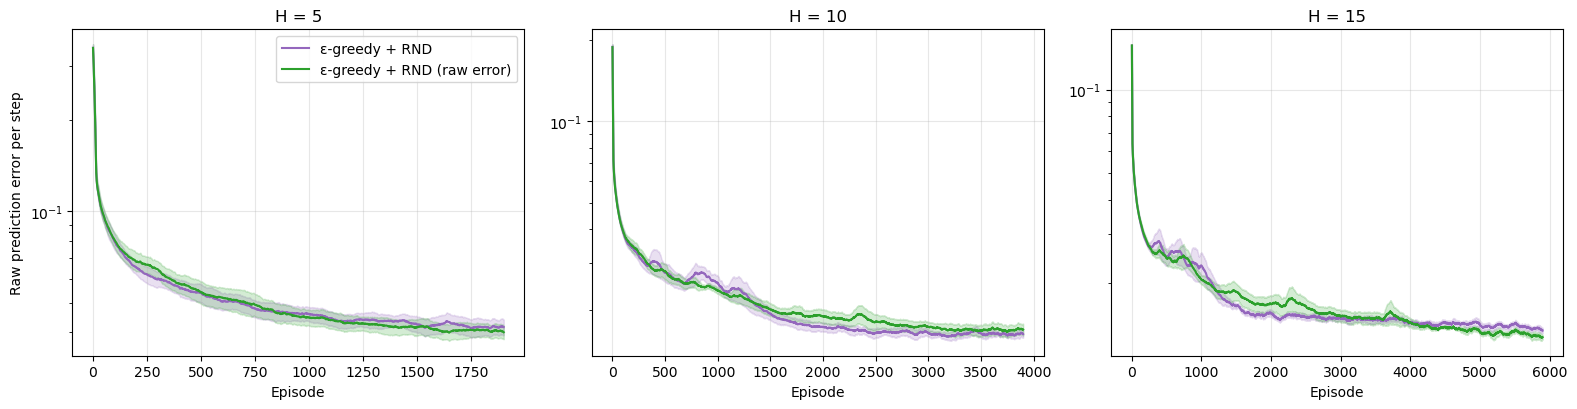

In [ ]:
fig, axes = plt.subplots(1, len(HORIZONS), figsize=(5.3 * len(HORIZONS), 4.2), squeeze=False)
axes = axes[0]
for ax, H in zip(axes, HORIZONS):
    for name in AGENTS[1:]:
        errors = np.array([smooth(h["rnd_error"]) for h in results[H][name]])
        episodes = np.arange(errors.shape[1])
        plot_mean_se(ax, episodes, errors, color=COLORS[name], label=name)
    ax.set(title=f"H = {H}", xlabel="Episode", yscale="log")
    ax.grid(alpha=0.3)
axes[0].set_ylabel("Raw prediction error per step")
axes[0].legend(loc="upper right")
plt.tight_layout()
plt.show()

## 5. Discussion

- **ε-greedy** finds the reward only by chance, and the misleading reward pulls it into the bad chain.
- **RND** keeps a high bonus on rarely visited states deep in the good chain, which pulls the agent forward. In our runs it reaches the best possible success rate sooner at every horizon. Its first success comes about 1.5 to 4 times earlier on average, although a few seeds show little difference.
- **Normalizing the bonus matters.** The raw prediction error is smaller for longer locks (their observations are larger) and keeps shrinking during training, so with a fixed β the raw-error bonus becomes too weak at $H = 15$. Dividing by the error's running std keeps the bonus on the same scale at every horizon.
- **Why does ε-greedy succeed at all?** Likely because the Q-network's estimates for unvisited good states are arbitrary, and the max over them acts as accidental optimism. RND makes that optimism deliberate.
- **Link to UCB:** both bonuses shrink with visits and steer the agent toward what it knows least.
- **Limitations:** observations with irreducible noise can trap RND (the "noisy TV" problem), and our locks, budgets and seed counts are small.

**References.** Burda et al. (2019), *Exploration by Random Network Distillation*, ICLR. Misra et al. (2020), *Kinematic State Abstraction and Provably Efficient Rich-Observation RL*, ICML.